# SVD Image Compression

## Libraries import

In [1]:
from os.path import join
import random
import struct
from array import array
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

## MNIST dataset import ([Code source](https://www.kaggle.com/code/hojjatk/read-mnist-dataset))

In [2]:
class MnistDataloader(object):
    def __init__(self, training_images_filepath,training_labels_filepath,
                 test_images_filepath, test_labels_filepath):
        self.training_images_filepath = training_images_filepath
        self.training_labels_filepath = training_labels_filepath
        self.test_images_filepath = test_images_filepath
        self.test_labels_filepath = test_labels_filepath
    
    def read_images_labels(self, images_filepath, labels_filepath):        
        labels = []
        with open(labels_filepath, 'rb') as file:
            magic, size = struct.unpack(">II", file.read(8))
            if magic != 2049:
                raise ValueError('Magic number mismatch, expected 2049, got {}'.format(magic))
            labels = array("B", file.read())        
        
        with open(images_filepath, 'rb') as file:
            magic, size, rows, cols = struct.unpack(">IIII", file.read(16))
            if magic != 2051:
                raise ValueError('Magic number mismatch, expected 2051, got {}'.format(magic))
            image_data = array("B", file.read())        
        images = []
        for i in range(size):
            images.append([0] * rows * cols)
        for i in range(size):
            img = np.array(image_data[i * rows * cols:(i + 1) * rows * cols])
            img = img.reshape(28, 28)
            images[i][:] = img            
        
        return images, labels
            
    def load_data(self):
        x_train, y_train = self.read_images_labels(self.training_images_filepath, self.training_labels_filepath)
        x_test, y_test = self.read_images_labels(self.test_images_filepath, self.test_labels_filepath)
        return (x_train, y_train),(x_test, y_test)

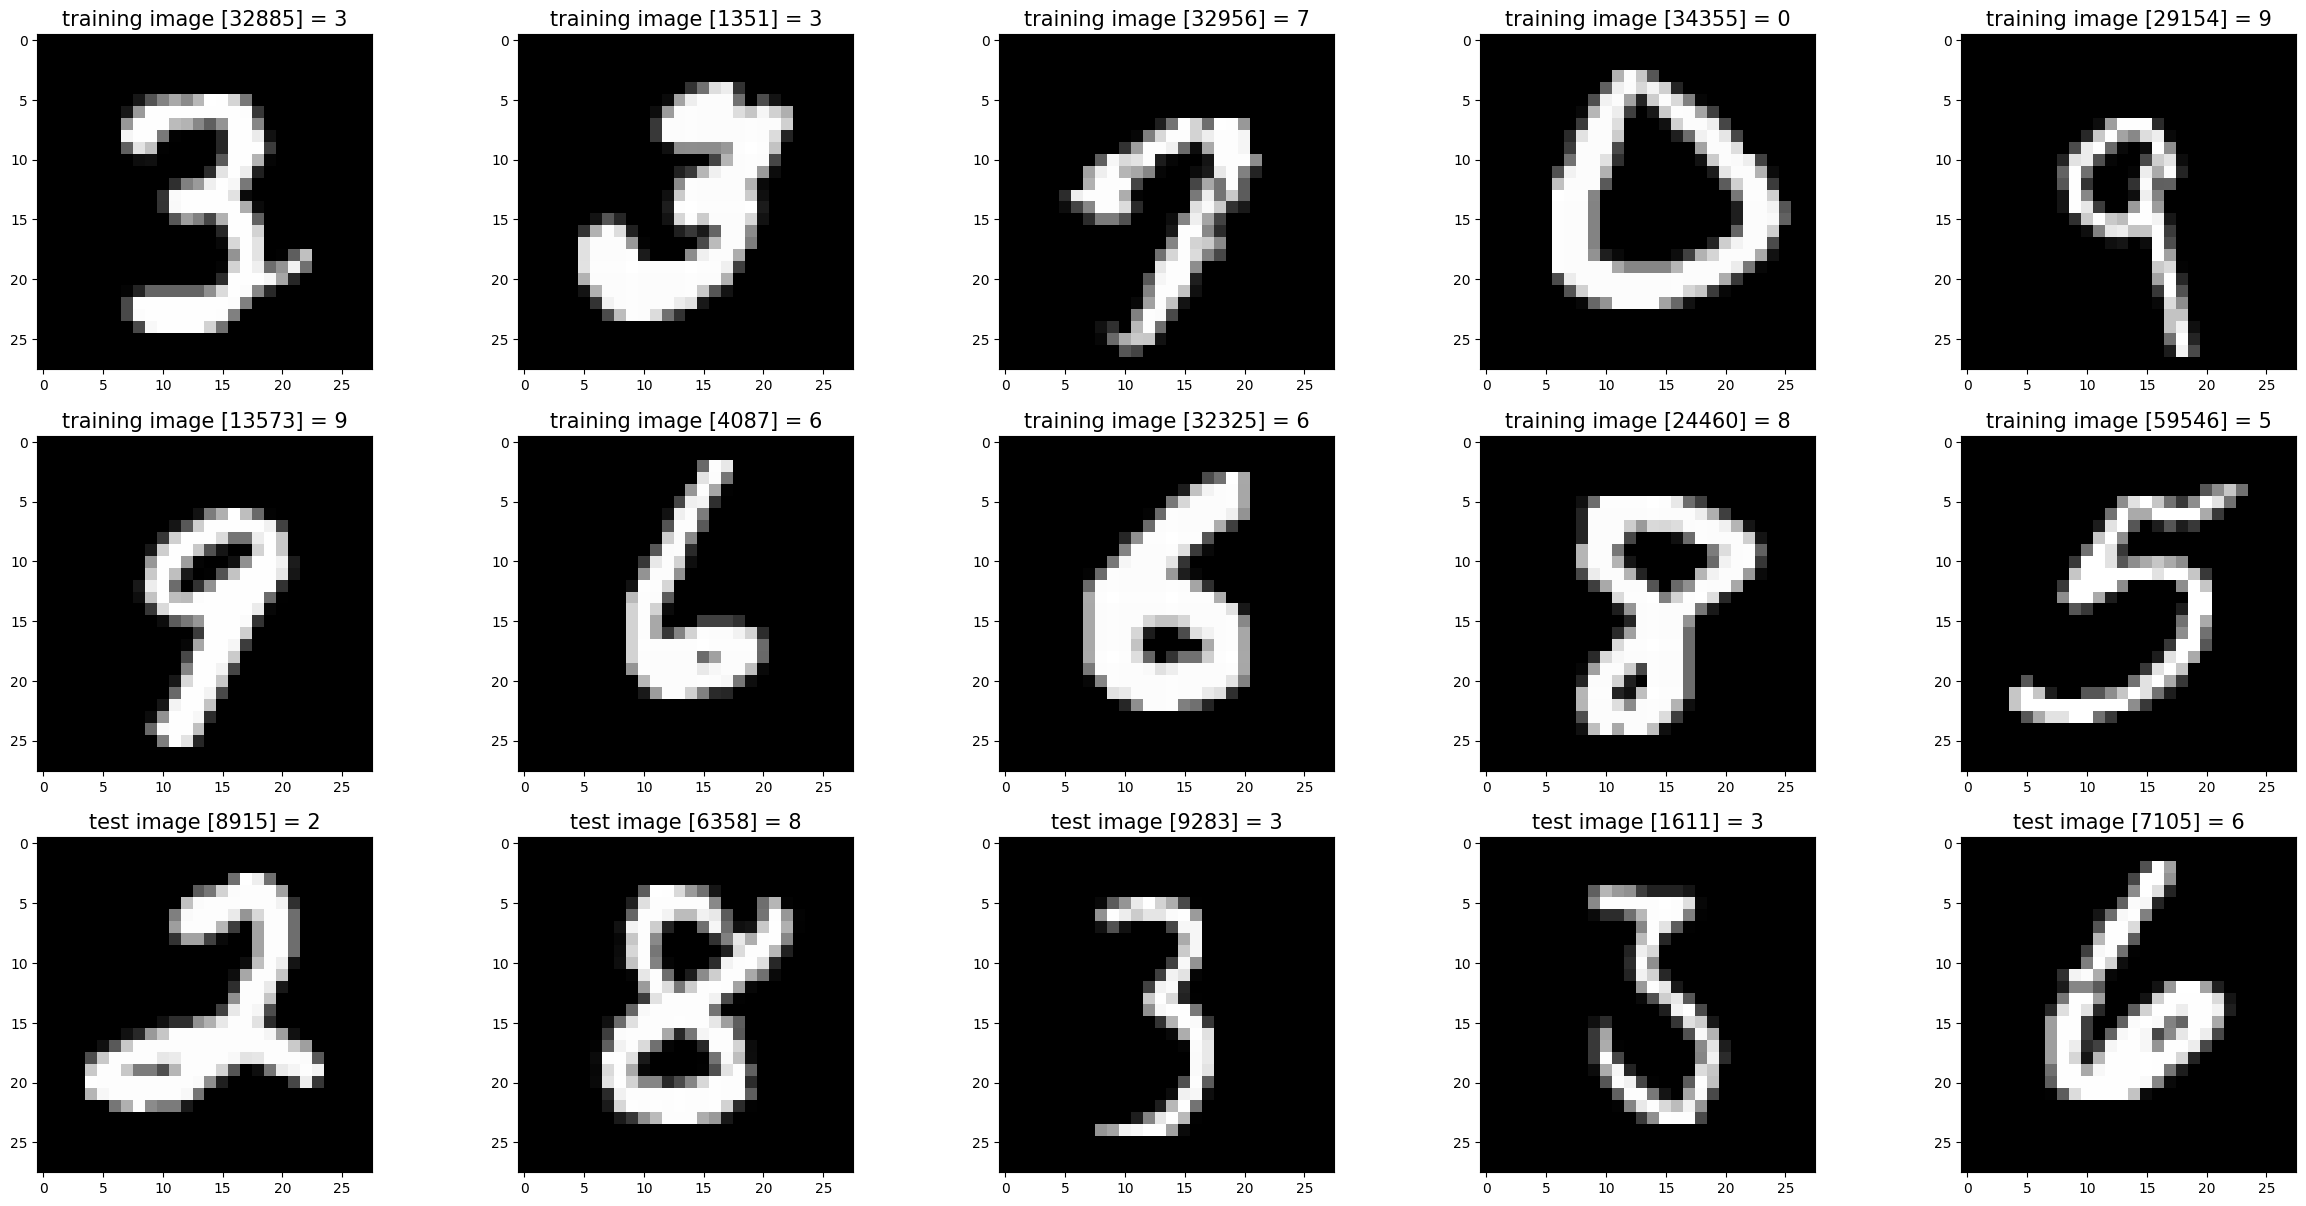

In [3]:
input_path = ''
training_images_filepath = join(input_path, 'train-images-idx3-ubyte/train-images-idx3-ubyte')
training_labels_filepath = join(input_path, 'train-labels-idx1-ubyte/train-labels-idx1-ubyte')
test_images_filepath = join(input_path, 't10k-images-idx3-ubyte/t10k-images-idx3-ubyte')
test_labels_filepath = join(input_path, 't10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte')

# Helper function to show a list of images with their relating titles
def show_images(images, title_texts):
    cols = 5
    rows = int(len(images)/cols) + 1
    plt.figure(figsize=(30,20))
    index = 1    
    for x in zip(images, title_texts):        
        image = x[0]        
        title_text = x[1]
        plt.subplot(rows, cols, index)        
        plt.imshow(image, cmap=plt.cm.gray)
        if (title_text != ''):
            plt.title(title_text, fontsize = 15);        
        index += 1

# Load MINST dataset
mnist_dataloader = MnistDataloader(training_images_filepath, training_labels_filepath, test_images_filepath, test_labels_filepath)
(x_train, y_train), (x_test, y_test) = mnist_dataloader.load_data()

# Show some random training and test images 
images_2_show = []
titles_2_show = []
for i in range(0, 10):
    r = random.randrange(len(x_train))
    images_2_show.append(x_train[r])
    titles_2_show.append('training image [' + str(r) + '] = ' + str(y_train[r]))    

for i in range(0, 5):
    r = random.randrange(len(x_test))
    images_2_show.append(x_test[r])        
    titles_2_show.append('test image [' + str(r) + '] = ' + str(y_test[r]))    

show_images(images_2_show, titles_2_show)

## Images as vectors

In [4]:
# Convert each 28 x 28 image into a vector of 784 pixels
X_train = np.asarray(x_train, dtype=np.uint8).reshape(len(x_train), -1)
X_test = np.asarray(x_test, dtype=np.uint8).reshape(len(x_test), -1)
y_train = np.asarray(y_train)
y_test = np.asarray(y_test)

print(f'Train: {X_train.shape} | Test: {X_test.shape}')

Train: (60000, 784) | Test: (10000, 784)


In [ ]:
from sklearn.model_selection import train_test_split

# Use stratified sample for all methods to limit fitting time
sample_size = 3000
sample_idx, _ = train_test_split(np.arange(len(X_train)), train_size=sample_size,
                                 stratify=y_train, random_state=42)
X = X_train[sample_idx].astype(np.float32) / 255
y = y_train[sample_idx]

print(f'Sample shape: {X.shape}')
display(pd.Series(y).value_counts().sort_index().rename('Images per digit'))

Sample shape: (3000, 784)


0    296
1    337
2    298
3    307
4    292
5    271
6    296
7    313
8    293
9    297
Name: Images per digit, dtype: int64

## Dimensionality reduction
All six methods use the same 3000 images and 784 normalized pixel features. Labels are used only for visualization and evaluation. PCA centers the data; SVD and Randomized-SVD below use the uncentered matrix.

In [6]:
from sklearn.decomposition import PCA
from sklearn.utils.extmath import randomized_svd
from sklearn.manifold import TSNE, LocallyLinearEmbedding
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score
import umap

embeddings = {}
fitting_times = {}
n_components = 2

### PCA, SVD and Randomized-SVD

In [ ]:
# PCA (SVD with centering)
t0 = time.time()
pca = PCA(n_components=n_components, svd_solver='full')
embeddings['PCA'] = pca.fit_transform(X)
fitting_times['PCA'] = time.time() - t0

# Just SVD (without centering)
t0 = time.time()
U, s, Vt = np.linalg.svd(X, full_matrices=False)
embeddings['SVD'] = U[:, :n_components] * s[:n_components]
fitting_times['SVD'] = time.time() - t0

# Randomized SVD
t0 = time.time()
U_random, s_random, Vt_random = randomized_svd(X, n_components=n_components,
                                             n_iter=7, random_state=42)
embeddings['Randomized-SVD'] = U_random * s_random
fitting_times['Randomized-SVD'] = time.time() - t0

# TSNE
t0 = time.time()
tsne = TSNE(n_components=n_components, perplexity=30, learning_rate='auto',
            init='pca', random_state=42)
embeddings['TSNE'] = tsne.fit_transform(X)
fitting_times['TSNE'] = time.time() - t0

# UMAP
t0 = time.time()
umap_reducer = umap.UMAP(n_components=n_components, n_neighbors=15, min_dist=0.1,
                         random_state=42, n_jobs=1)
embeddings['UMAP'] = umap_reducer.fit_transform(X)
fitting_times['UMAP'] = time.time() - t0

# LLE
t0 = time.time()
lle = LocallyLinearEmbedding(n_components=n_components, n_neighbors=30,
                             eigen_solver='dense', random_state=42)
embeddings['LLE'] = lle.fit_transform(X)
fitting_times['LLE'] = time.time() - t0

### Visualizations

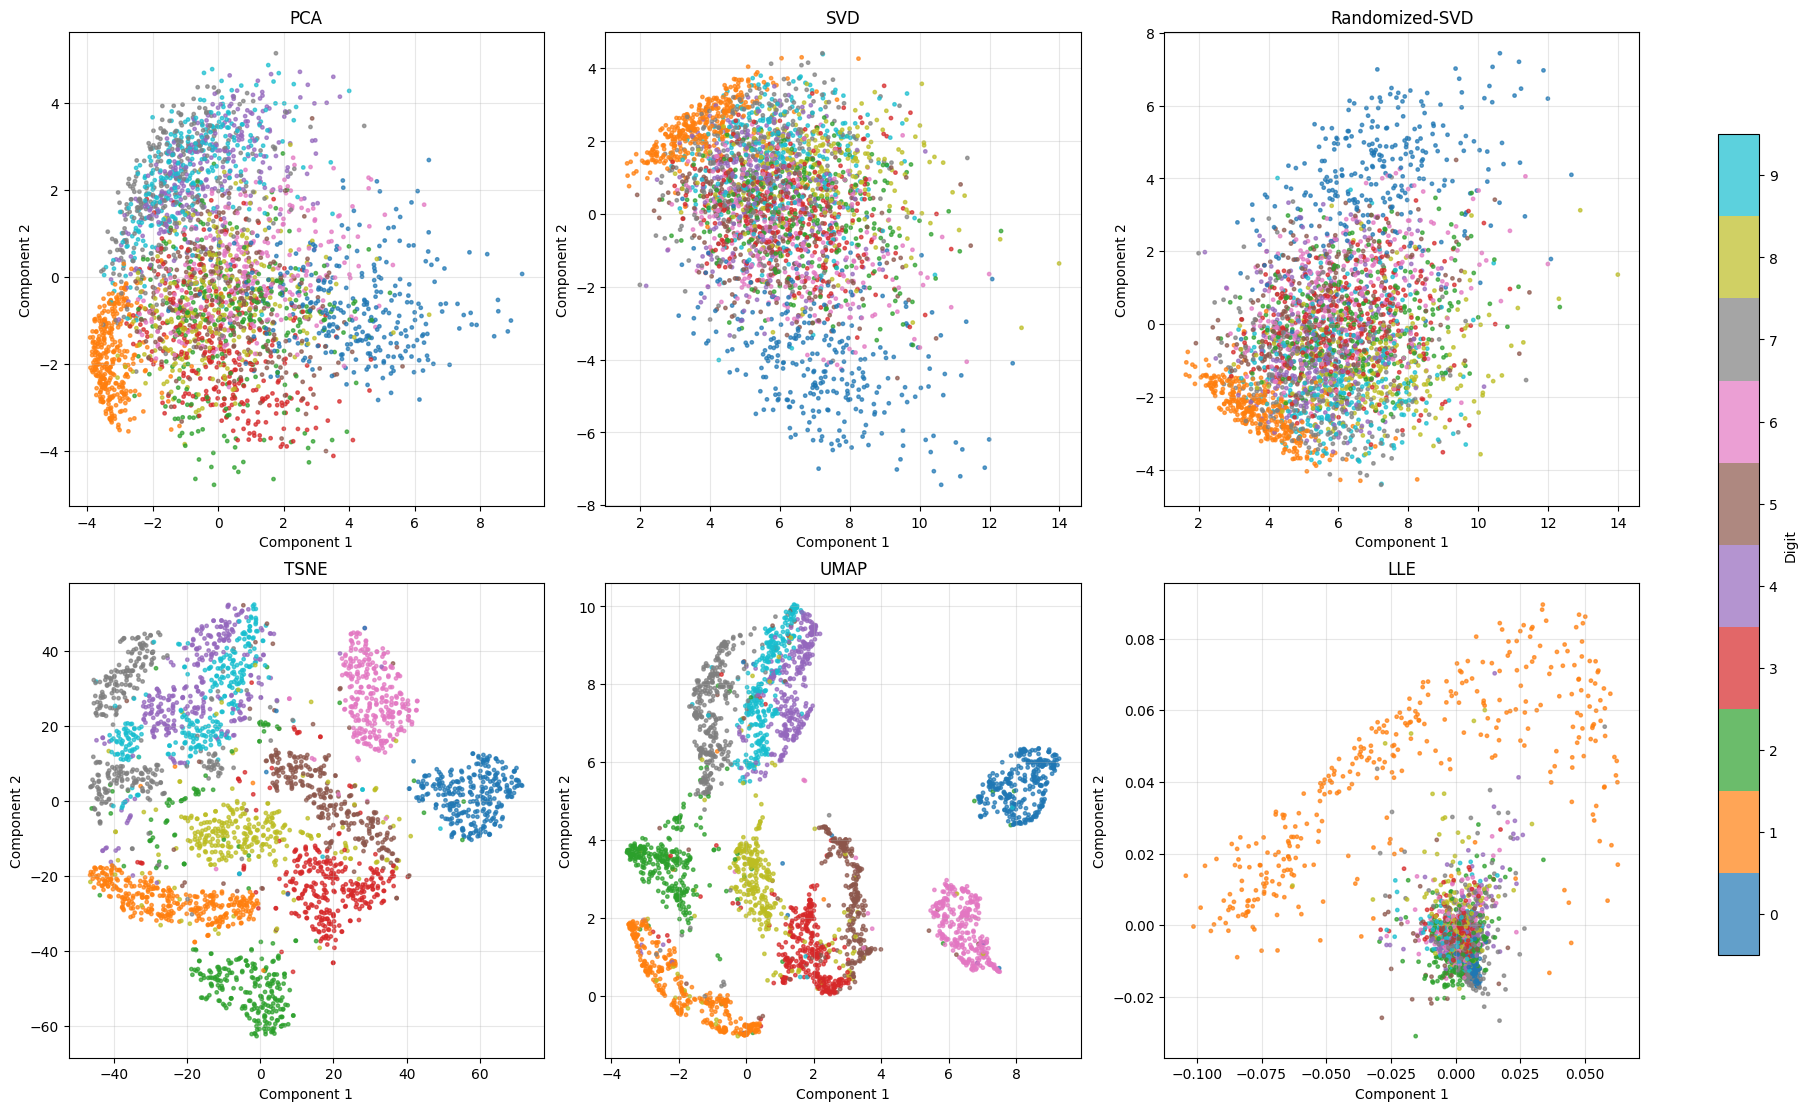

In [9]:
fig, ax = plt.subplots(ncols=3, nrows=2, figsize=(18, 11), constrained_layout=True)

for axis, (name, embedding) in zip(ax.ravel(), embeddings.items()):
    points = axis.scatter(embedding[:, 0], embedding[:, 1], c=y, cmap='tab10',
                          vmin=-0.5, vmax=9.5, s=6, alpha=0.7)
    axis.set_title(name)
    axis.set_xlabel('Component 1')
    axis.set_ylabel('Component 2')
    axis.grid(True, alpha=0.3)

fig.colorbar(points, ax=ax.ravel().tolist(), ticks=range(10), label='Digit', shrink=0.8)
plt.show()

### Models comparison
Silhouette score compares within-class distances with distances to the nearest other class: higher is better (range -1 to 1). Davies-Bouldin compares class scatter with distances between class centers: lower is better. Both use the digit labels as classes.

10-neighbor purity is the fraction of the ten nearest neighbors with the same digit label, excluding the point itself: higher is better (range 0 to 1). It measures local class separation, not accuracy on unseen images. These metrics describe this sample and these settings; nonlinear embeddings can distort global distances.

In [ ]:
results = []

for name, embedding in embeddings.items():
    neighbors = NearestNeighbors(n_neighbors=10).fit(embedding)
    # With no query matrix, kneighbors excludes each point itself
    neighbor_idx = neighbors.kneighbors(return_distance=False)
    purity = np.mean(y[neighbor_idx] == y[:, None])
    results.append([name, silhouette_score(embedding, y),
                    davies_bouldin_score(embedding, y), purity, fitting_times[name]])

results_df = pd.DataFrame(results, columns=['method', 'Silhouette', 'Davies-Bouldin',
                                            '10-neighbor purity', 'Fitting time (s)'])
results_df = results_df.sort_values('10-neighbor purity', ascending=False).reset_index(drop=True)
display(results_df.round(4))

print('Best local class separation:', results_df.loc[0, 'method'])
print('Best silhouette:', results_df.loc[results_df['Silhouette'].idxmax(), 'method'])
print('Lowest Davies-Bouldin:', results_df.loc[results_df['Davies-Bouldin'].idxmin(), 'method'])

,method,Silhouette,Davies-Bouldin,10-neighbor purity,Fitting time (s)
0,TSNE,0.2477,2.7006,0.8599,17.8234
1,UMAP,0.3186,1.6124,0.8562,67.5880
2,PCA,0.0137,5.3068,0.3658,3.2877
3,LLE,-0.1367,10.3367,0.2878,5.1544
4,SVD,-0.0411,6.0973,0.2798,1.8284
5,Randomized-SVD,-0.0411,6.0973,0.2798,0.0481


Best local class separation: TSNE
Best silhouette: UMAP
Lowest Davies-Bouldin: UMAP


## Image compression using SVD
### Random grayscale images

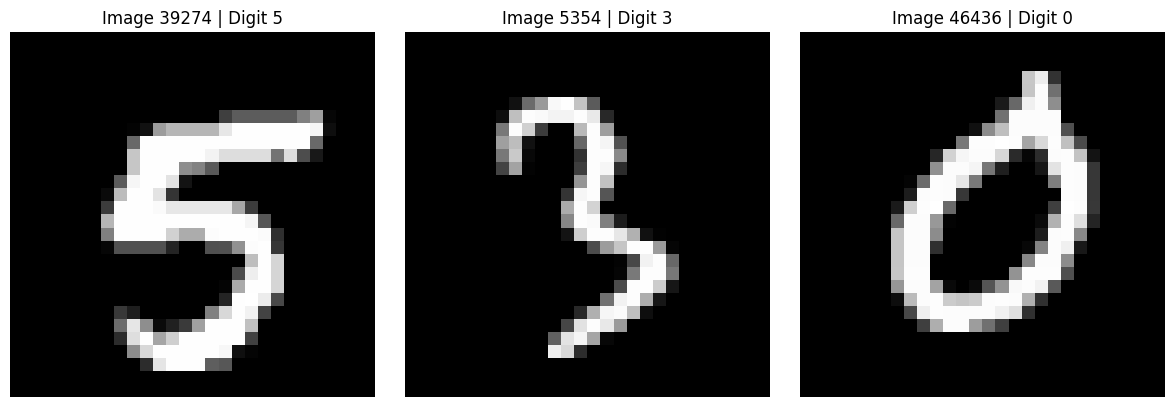

In [11]:
# Select three random MNIST images without replacement
rng = np.random.default_rng(42)
image_idx = rng.choice(len(x_train), size=3, replace=False)
images = np.asarray([x_train[i] for i in image_idx], dtype=np.float64) / 255

fig, ax = plt.subplots(ncols=3, nrows=1, figsize=(12, 4))
for axis, image, idx in zip(ax, images, image_idx):
    axis.imshow(image, cmap='gray', vmin=0, vmax=1)
    axis.set_title(f'Image {idx} | Digit {y_train[idx]}')
    axis.axis('off')
plt.tight_layout()
plt.show()

### SVD decomposition and low-rank approximation
For an image matrix $A = U\Sigma V^T$, the rank-$k$ approximation is $A_k = U_{:,1:k}\Sigma_{1:k,1:k}V^T_{1:k,:}$. It minimizes the squared reconstruction error among matrices of rank at most $k$.

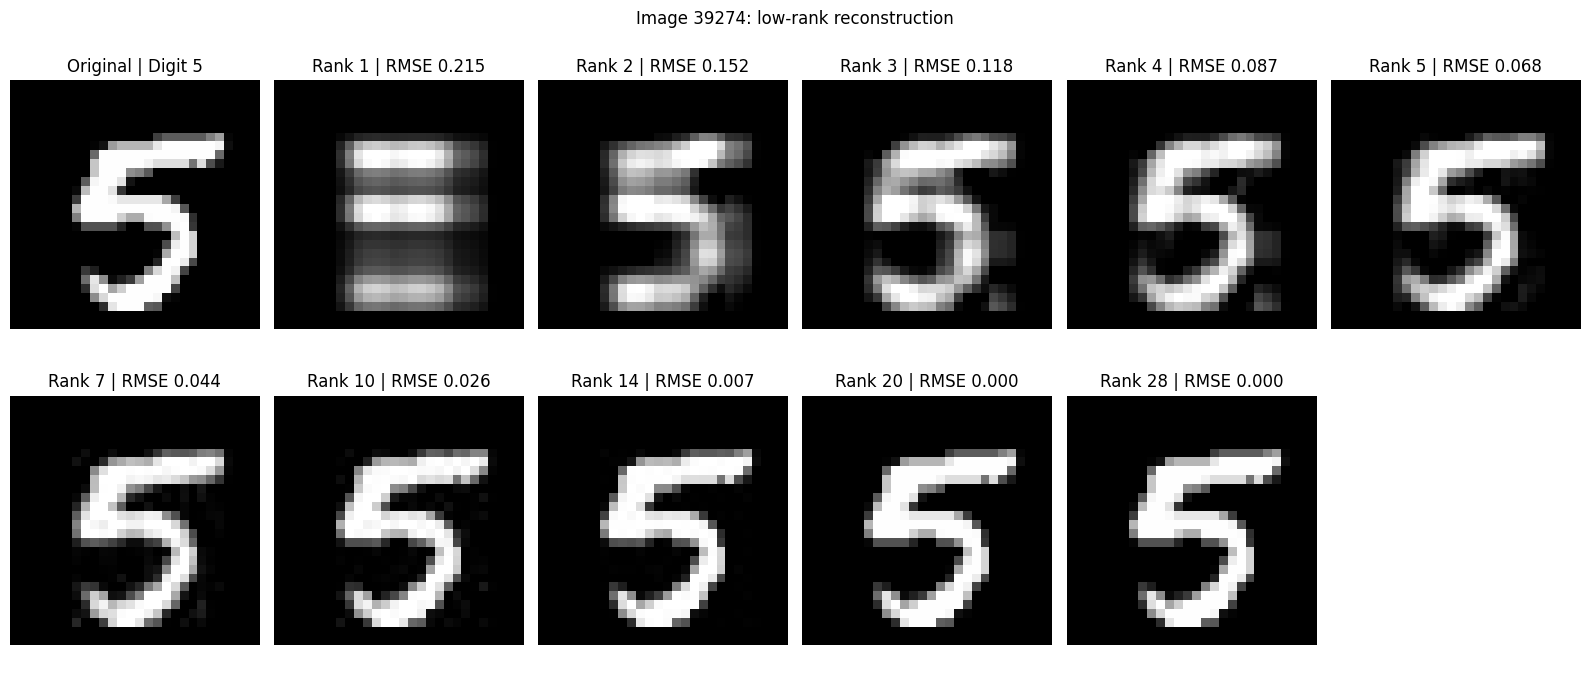

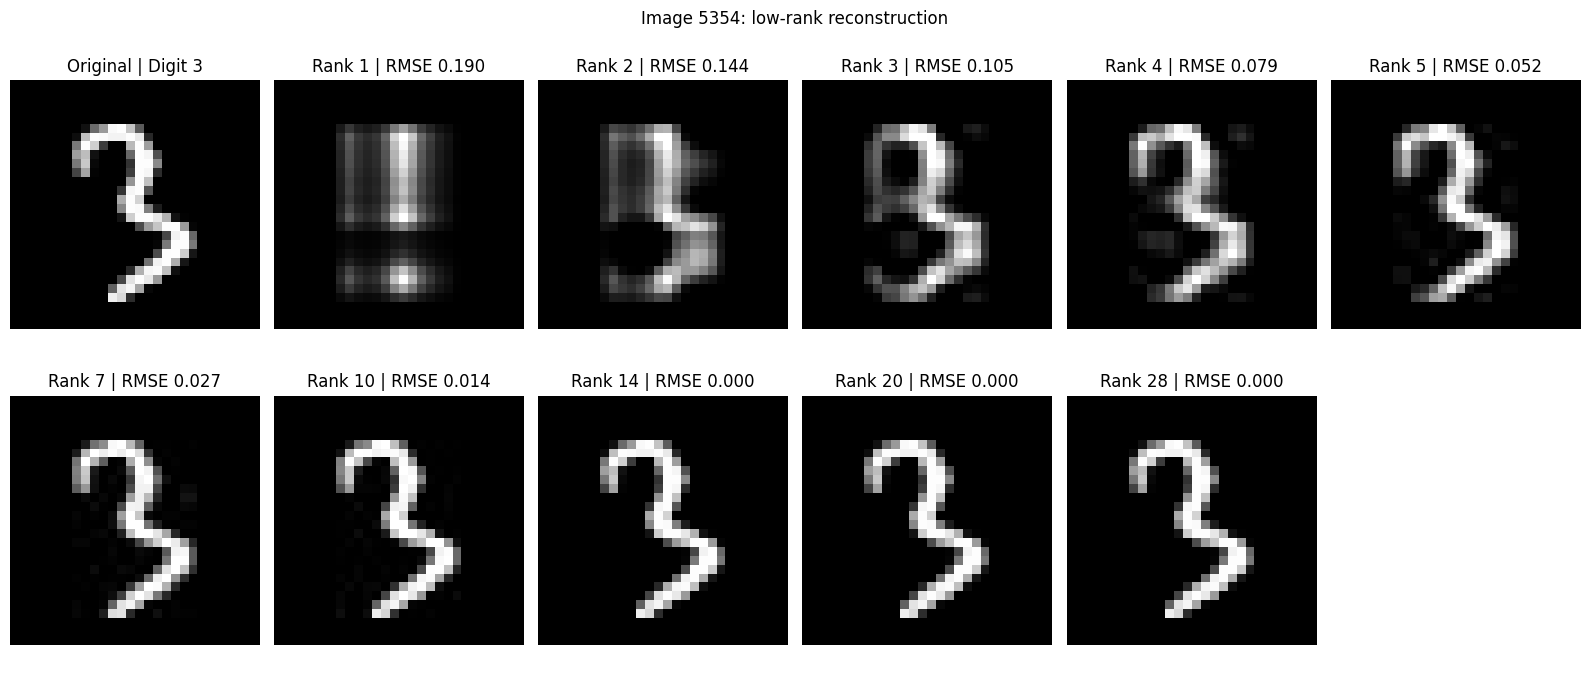

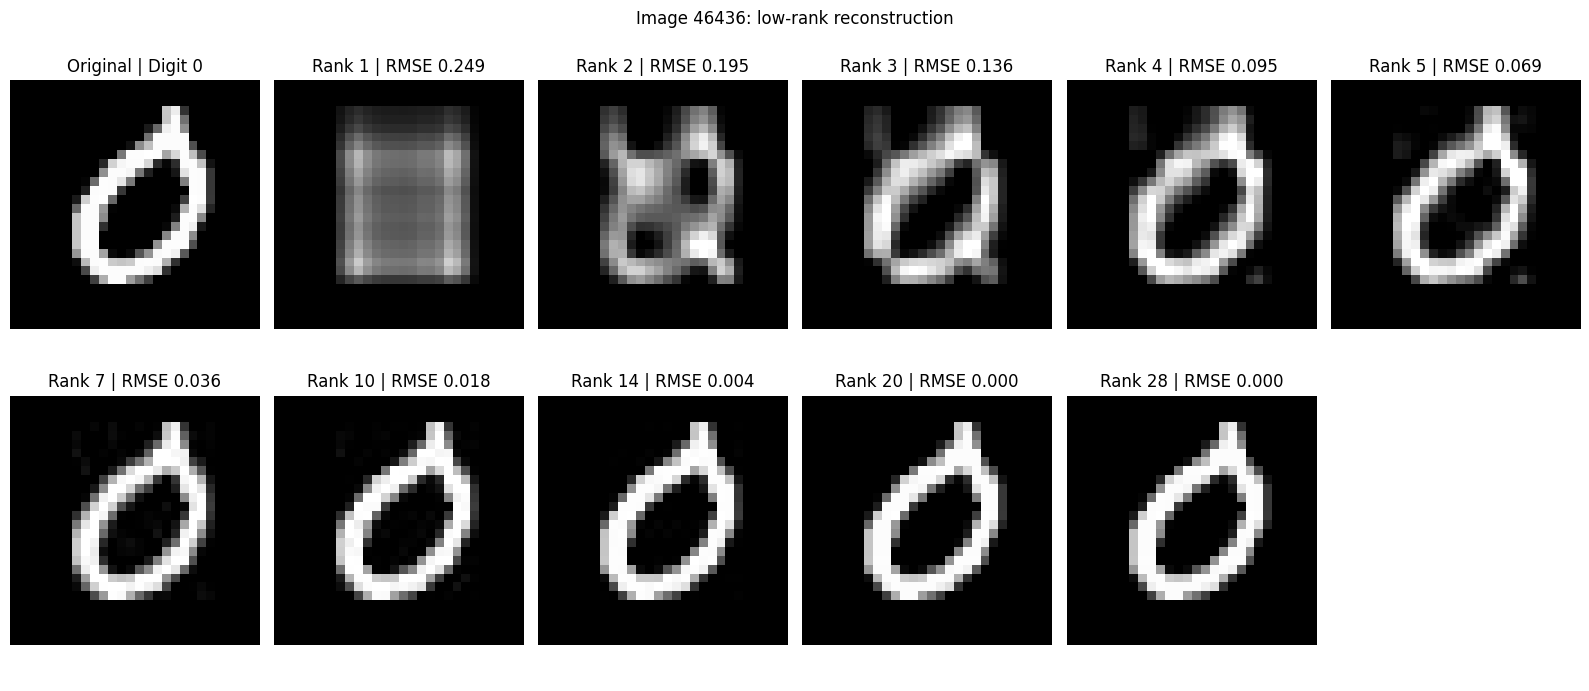

In [12]:
decompositions = [np.linalg.svd(image, full_matrices=False) for image in images]
ranks = [1, 2, 3, 4, 5, 7, 10, 14, 20, 28]
compression_results = []

for image, idx, (U_img, s_img, Vt_img) in zip(images, image_idx, decompositions):
    fig, ax = plt.subplots(ncols=6, nrows=2, figsize=(16, 7))
    ax = ax.ravel()
    ax[0].imshow(image, cmap='gray', vmin=0, vmax=1)
    ax[0].set_title(f'Original | Digit {y_train[idx]}')

    for axis, rank in zip(ax[1:], ranks):
        recovered = (U_img[:, :rank] * s_img[:rank]) @ Vt_img[:rank, :]
        rmse = np.sqrt(np.mean((image - recovered) ** 2))
        energy = np.sum(s_img[:rank] ** 2) / np.sum(s_img ** 2)
        compression_results.append([idx, rank, rmse, energy])
        # Clip only for display; compute the error on the actual approximation
        axis.imshow(np.clip(recovered, 0, 1), cmap='gray', vmin=0, vmax=1)
        axis.set_title(f'Rank {rank} | RMSE {rmse:.3f}')

    for axis in ax:
        axis.axis('off')
    fig.suptitle(f'Image {idx}: low-rank reconstruction')
    plt.tight_layout(h_pad=2)
    plt.show()

compression_df = pd.DataFrame(compression_results,
                              columns=['Image', 'Rank', 'RMSE', 'Retained energy'])

### Singular value spectrum

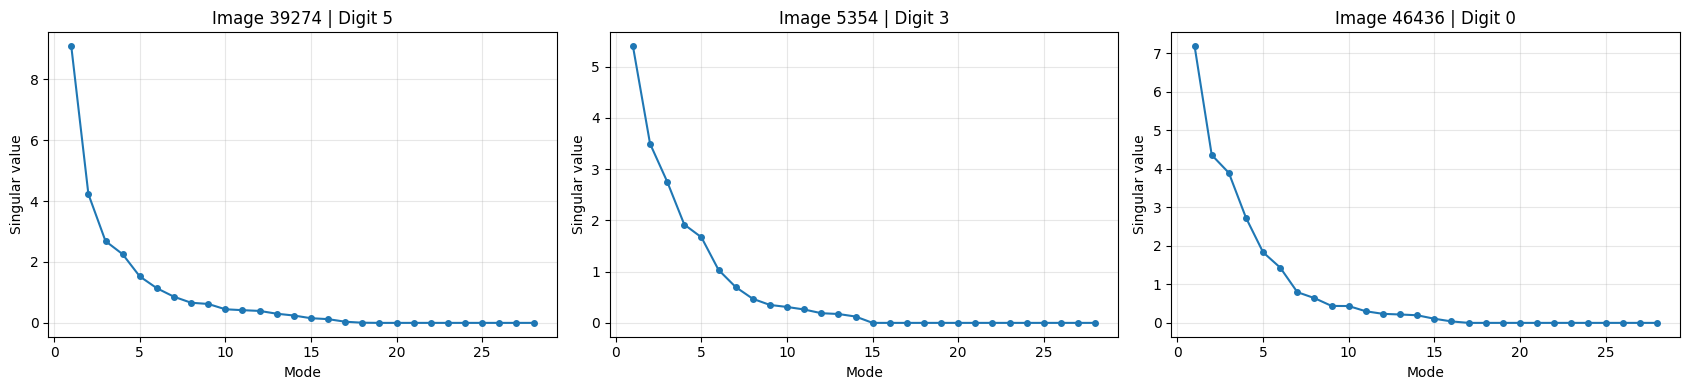

In [13]:
fig, ax = plt.subplots(ncols=3, nrows=1, figsize=(17, 4))

for axis, idx, (_, s_img, _) in zip(ax, image_idx, decompositions):
    axis.plot(np.arange(1, len(s_img) + 1), s_img, marker='o', markersize=4)
    axis.set_title(f'Image {idx} | Digit {y_train[idx]}')
    axis.set_xlabel('Mode')
    axis.set_ylabel('Singular value')
    axis.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Explained variance versus rank
Explained variance is the fraction of total variation captured by the retained components. For centered data in PCA, it equals $\sum_{i=1}^k\sigma_i^2 / \sum_i\sigma_i^2$.

Here images are decomposed **without centering**, so the same ratio measures retained squared pixel energy rather than variance around the mean. We use this energy interpretation of explained variance for image compression:

$$E(k)=\frac{\sum_{i=1}^k\sigma_i^2}{\sum_i\sigma_i^2}=1-\frac{\lVert A-A_k\rVert_F^2}{\lVert A\rVert_F^2}.$$

The bars show individual mode contributions; the curve shows their cumulative sum. We use 99% retained energy as a numerical reconstruction criterion and compare it with the recovered images. It corresponds to a relative Frobenius error of at most 10%, not a universal perceptual threshold.

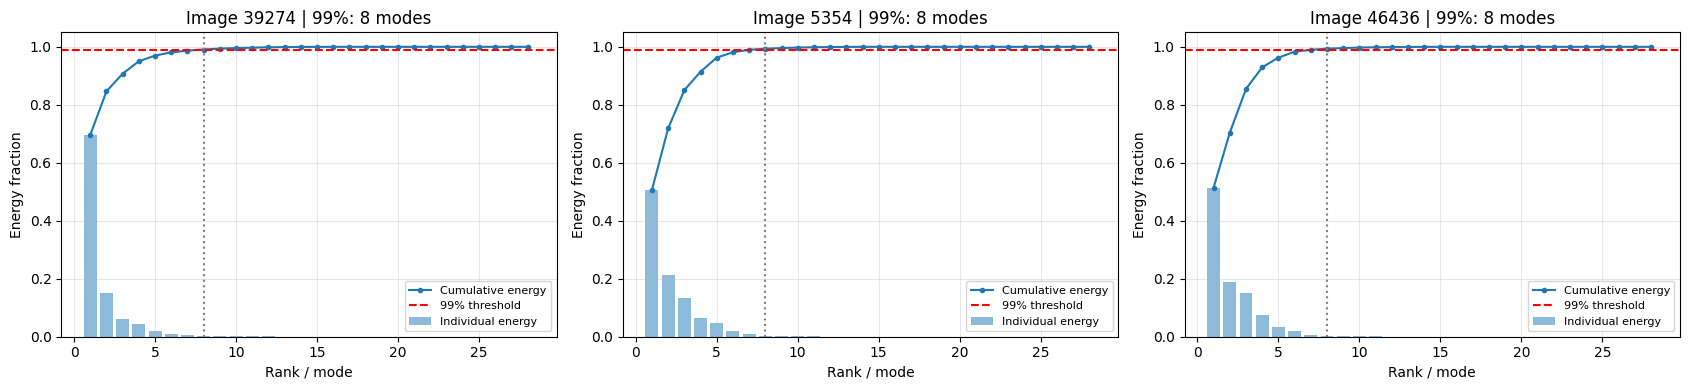

,Image,Digit,Rank for 95%,Rank for 99%,Stored values / original
0,39274,5,4,8,0.5816
1,5354,3,5,8,0.5816
2,46436,0,5,8,0.5816


Image,5354,39274,46436
Rank,,,
1,0.19044,0.21455,0.24914
2,0.14380,0.15237,0.19457
3,0.10483,0.11840,0.13616
4,0.07935,0.08677,0.09510
5,0.05234,0.06751,0.06903
7,0.02742,0.04434,0.03648
10,0.01381,0.02570,0.01770
14,0.00000,0.00716,0.00408
20,0.00000,0.00000,0.00000


In [14]:
fig, ax = plt.subplots(ncols=3, nrows=1, figsize=(17, 4))
summary = []

for axis, idx, (_, s_img, _) in zip(ax, image_idx, decompositions):
    energy_ratio = s_img ** 2 / np.sum(s_img ** 2)
    cumulative_energy = np.cumsum(energy_ratio)
    modes = np.arange(1, len(s_img) + 1)
    rank_95 = np.searchsorted(cumulative_energy, 0.95) + 1
    rank_99 = np.searchsorted(cumulative_energy, 0.99) + 1
    # Number of stored values in U_k, s_k and Vt_k relative to the image
    storage_ratio = rank_99 * (images.shape[1] + images.shape[2] + 1) / images[0].size
    summary.append([idx, y_train[idx], rank_95, rank_99, storage_ratio])

    axis.bar(modes, energy_ratio, alpha=0.5, label='Individual energy')
    axis.plot(modes, cumulative_energy, marker='o', markersize=3, label='Cumulative energy')
    axis.axhline(0.99, color='red', linestyle='--', label='99% threshold')
    axis.axvline(rank_99, color='gray', linestyle=':')
    axis.set_title(f'Image {idx} | 99%: {rank_99} modes')
    axis.set_xlabel('Rank / mode')
    axis.set_ylabel('Energy fraction')
    axis.set_ylim(0, 1.05)
    axis.grid(True, alpha=0.3)
    axis.legend(fontsize=8)

plt.tight_layout()
plt.show()

summary_df = pd.DataFrame(summary, columns=['Image', 'Digit', 'Rank for 95%',
                                          'Rank for 99%', 'Stored values / original'])
display(summary_df.round(4))
display(compression_df.pivot(index='Rank', columns='Image', values='RMSE').round(5))